# Chapter 8 — Learning Signal and Ignoring Noise: Regularization and Batching
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

A network that reaches zero training error has not necessarily learned anything useful: it may simply have **memorized** its
training set, noise included. This chapter is about the difference between *signal* (patterns that hold for new data) and *noise*
(accidents of the particular examples), and about the tools that push a network towards learning signal:

- **early stopping** — stop training before the network starts memorizing,
- **weight decay (L2 regularization)** — penalize large weights,
- **dropout** — randomly silence hidden units during training,
- **mini-batches** — update the weights from small groups of examples rather than the whole set.

> **Note on the examples.** The book uses a subset of the MNIST digits. Here I use the small **8×8 digit images that ship with scikit-learn**,
> and — to make overfitting *visible* on such an easy dataset — I deliberately train on only 300 images, **25% of which get a wrong label**
> (a very realistic situation: human labelers make mistakes). The test set is clean. The code, the setup and the numbers are my own;
> the concepts and their order follow the chapter.

**Roadmap**
1. Overfitting: watching a network memorize noise
2. Early stopping
3. L2 regularization (weight decay)
4. Dropout
5. Mini-batch gradient descent
6. Putting it together (several random seeds)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=3, suppress=True)

digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target
order = np.random.default_rng(0).permutation(len(X_all))
tr_idx, va_idx, te_idx = order[:300], order[300:500], order[1200:]

noise_rng = np.random.default_rng(100)
def add_label_noise(labels, frac=0.25):
    labels = labels.copy()
    flip = noise_rng.choice(len(labels), int(frac * len(labels)), replace=False)
    labels[flip] = (labels[flip] + noise_rng.integers(1, 10, size=len(flip))) % 10      # always a *wrong* label
    flipped = np.zeros(len(labels), dtype=bool); flipped[flip] = True
    return labels, flipped

Xtr, Xva, Xte = X_all[tr_idx], X_all[va_idx], X_all[te_idx]
ytr, flipped_tr = add_label_noise(y_all[tr_idx])      # noisy training labels
yva, _ = add_label_noise(y_all[va_idx])               # validation labels are noisy in the same way
yte = y_all[te_idx]                                   # test labels are clean
Ttr, Tte = np.eye(10)[ytr], np.eye(10)[yte]

print(f"train: {len(Xtr)} images ({flipped_tr.sum()} with a wrong label),  validation: {len(Xva)},  test: {len(Xte)} (clean)")

train: 300 images (75 with a wrong label),  validation: 200,  test: 597 (clean)


## 1. Overfitting: watching a network memorize noise

**Definition.** A model *overfits* when its error on the training data keeps improving while its error on **new** data stops improving or gets worse.
The model is no longer extracting the general rule ("what a 7 looks like") but memorizing individual examples ("this particular smudged image is called 4").

**Why it happens.** A flexible network (here $64\times256$ + $256\times10$ ≈ 19,000 weights for only 300 examples) can fit *any* labels, including wrong ones.
Early in training it can only capture the strong, shared patterns (signal). Later, the only way left to reduce training error is to bend itself around the
individual mislabeled examples (noise).

We train a one-hidden-layer ReLU network with the Chapter 6 backpropagation, using mini-batches of 20 (Section 5 explains batches). We track, every epoch:
accuracy on the noisy training labels, accuracy on the clean test set, and the **fraction of the mislabeled training images that the network now "agrees with"** —
a direct measure of memorization.

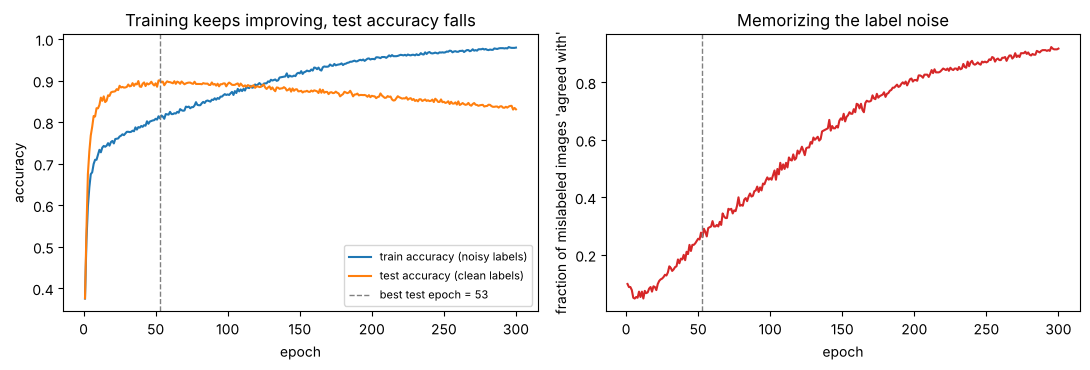

mean over 5 seeds: best test accuracy 0.901 at epoch 53;  final test accuracy 0.831;  final train accuracy 0.979
fraction of mislabeled training images fitted: epoch 53: 0.26   final epoch: 0.92


In [2]:
def train_run(seed, H=256, lr=0.05, epochs=300, batch=20, keep=1.0, l2=0.0):
    # ReLU network 64 -> H -> 10, mean-squared error on one-hot targets, optional dropout and L2 weight decay
    rng = np.random.default_rng(seed)
    W01 = rng.normal(0, 0.1, (64, H))
    W12 = rng.normal(0, 0.1, (H, 10))
    N = len(Xtr)
    log = {k: [] for k in ('train_acc', 'val_acc', 'test_acc', 'test_sse', 'memorized', 'w_norm')}
    predict = lambda X: np.maximum(0, X @ W01) @ W12

    for epoch in range(epochs):
        idx = rng.permutation(N)                                       # new random order every epoch
        for s in range(0, N, batch):
            b = idx[s:s + batch]
            xb, tb = Xtr[b], Ttr[b]
            z1 = xb @ W01
            l1 = np.maximum(0, z1)
            mask = (rng.random(l1.shape) < keep) / keep if keep < 1 else 1.0       # inverted dropout
            l1d = l1 * mask
            d2 = l1d @ W12 - tb                                        # output error
            d1 = (d2 @ W12.T) * mask * (z1 > 0)                        # blame back through W12, the dropout mask and the ReLU
            W12 -= lr * (l1d.T @ d2 / len(b) + l2 * W12)               # gradient step (+ weight decay)
            W01 -= lr * (xb.T @ d1 / len(b) + l2 * W01)

        ptr, pva, pte = predict(Xtr), predict(Xva), predict(Xte)       # evaluation: dropout is OFF
        log['train_acc'].append(np.mean(ptr.argmax(1) == ytr))
        log['val_acc'].append(np.mean(pva.argmax(1) == yva))
        log['test_acc'].append(np.mean(pte.argmax(1) == yte))
        log['test_sse'].append(np.mean(np.sum((pte - Tte) ** 2, axis=1)))
        log['memorized'].append(np.mean(ptr[flipped_tr].argmax(1) == ytr[flipped_tr]))
        log['w_norm'].append(np.sqrt(np.sum(W01 ** 2) + np.sum(W12 ** 2)))
    return {k: np.array(v) for k, v in log.items()}

_cache = {}
def runs(name, seeds=range(5), **kw):
    for s in seeds:
        if (name, s) not in _cache:
            _cache[(name, s)] = train_run(s, **kw)
    return [_cache[(name, s)] for s in seeds]

def mean_curve(rs, key):
    return np.mean([r[key] for r in rs], axis=0)

base = runs('baseline')
epochs_axis = np.arange(1, len(base[0]['test_acc']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(epochs_axis, mean_curve(base, 'train_acc'), label='train accuracy (noisy labels)')
axes[0].plot(epochs_axis, mean_curve(base, 'test_acc'), label='test accuracy (clean labels)')
peak = mean_curve(base, 'test_acc').argmax()
axes[0].axvline(peak + 1, color='gray', ls='--', lw=1, label=f'best test epoch = {peak + 1}')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('accuracy'); axes[0].set_title('Training keeps improving, test accuracy falls'); axes[0].legend(fontsize=8)
axes[1].plot(epochs_axis, mean_curve(base, 'memorized'), color='tab:red')
axes[1].axvline(peak + 1, color='gray', ls='--', lw=1)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel("fraction of mislabeled images 'agreed with'")
axes[1].set_title('Memorizing the label noise')
plt.tight_layout()
plt.savefig('outputs/overfitting_curves.png', dpi=110)
plt.show()

print(f"mean over 5 seeds: best test accuracy {mean_curve(base, 'test_acc').max():.3f} at epoch {peak + 1};  "
      f"final test accuracy {mean_curve(base, 'test_acc')[-1]:.3f};  final train accuracy {mean_curve(base, 'train_acc')[-1]:.3f}")
print(f"fraction of mislabeled training images fitted: epoch {peak + 1}: {mean_curve(base, 'memorized')[peak]:.2f}   final epoch: {mean_curve(base, 'memorized')[-1]:.2f}")

**Reading the output.** Training accuracy climbs towards 100% — *even though a quarter of the labels are wrong*, which is only possible if the network
fits the wrong labels. The right-hand plot confirms it: at the best test epoch the network "agrees" with only about a quarter of the mislabeled images (it mostly believes the true
pattern); by the end it agrees with about 92% of them. Meanwhile test accuracy peaks early and then **falls**: the more the network accommodates noise, the worse it behaves on clean new images.
This gap between training and test performance is overfitting.

## 2. Early stopping

The simplest remedy: **stop when generalization stops improving.** We cannot use the test set to decide (that would be cheating — the test set must stay untouched),
so we keep a separate **validation set** with labels collected the same way as the training labels. We train as usual, track validation accuracy each epoch, and
keep the epoch where it was highest.

epoch chosen by the validation set (per seed): [55, 105, 47, 36, 111]
test accuracy with early stopping : 0.894 (+/- 0.003)
test accuracy at the final epoch  : 0.831


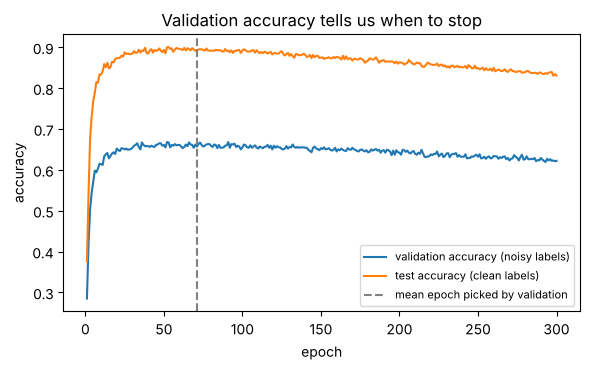

In [3]:
best_epochs = [int(r['val_acc'].argmax()) for r in base]
es_test = [r['test_acc'][e] for r, e in zip(base, best_epochs)]
print("epoch chosen by the validation set (per seed):", [e + 1 for e in best_epochs])
print(f"test accuracy with early stopping : {np.mean(es_test):.3f} (+/- {np.std(es_test):.3f})")
print(f"test accuracy at the final epoch  : {np.mean([r['test_acc'][-1] for r in base]):.3f}")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(epochs_axis, mean_curve(base, 'val_acc'), label='validation accuracy (noisy labels)')
ax.plot(epochs_axis, mean_curve(base, 'test_acc'), label='test accuracy (clean labels)')
ax.axvline(np.mean(best_epochs) + 1, color='gray', ls='--', label='mean epoch picked by validation')
ax.set_xlabel('epoch'); ax.set_ylabel('accuracy'); ax.set_title('Validation accuracy tells us when to stop'); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/early_stopping.png', dpi=110)
plt.show()

**Reading the output.** The validation curve rises and then falls at nearly the same moment as the test curve, even though the validation labels are themselves
noisy — so it is a good stand-in for the test set. Stopping at its peak recovers most of the lost test accuracy at zero extra cost. The price: you must set aside data for validation.

## 3. L2 regularization (weight decay)

Early stopping stops the network from *getting* too good at memorizing. Regularization instead makes memorizing **harder**.

**Idea.** To bend around individual noisy points, a network needs large weights (steep, wiggly functions). So add a penalty on the size of the weights to the error:

$$E_{\text{total}} = E_{\text{data}} + \frac{\lambda}{2}\sum_w w^2 \quad\Longrightarrow\quad \frac{\partial E_{\text{total}}}{\partial w}=\frac{\partial E_{\text{data}}}{\partial w}+\lambda\,w .$$

The gradient-descent update becomes

$$w \leftarrow w-\alpha\Bigl(\frac{\partial E_{\text{data}}}{\partial w}+\lambda w\Bigr) = \underbrace{(1-\alpha\lambda)}_{\text{shrink}}\,w-\alpha\frac{\partial E_{\text{data}}}{\partial w}.$$

So every step first **shrinks every weight slightly towards zero** ("weight decay"), then applies the usual correction. A weight survives only if the data keeps pushing it
up — i.e. if it is *consistently* useful. Weights that only help fit a single noisy example get pushed back down by the next batch and the decay.

$\lambda$ is a **hyper-parameter**: too small does nothing, too large crushes the weights and the network *under*-fits.

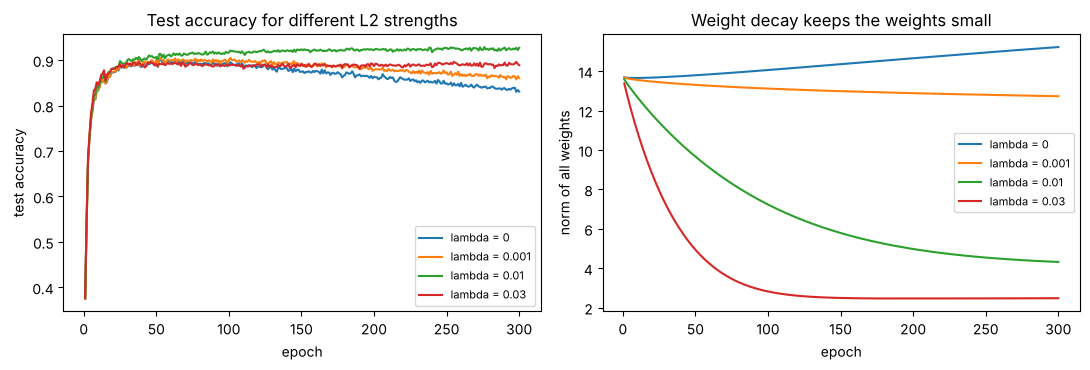

lambda | final train acc | final test acc | final weight norm
     0 |           0.979 |          0.831 | 15.22
 0.001 |           0.964 |          0.861 | 12.73
  0.01 |           0.783 |          0.927 | 4.32
  0.03 |           0.718 |          0.889 | 2.48


In [4]:
l2_values = [0.0, 1e-3, 1e-2, 3e-2]
l2_names = ['baseline', 'L2 1e-3', 'L2 1e-2', 'L2 3e-2']
l2_runs = [base] + [runs(n, l2=v) for n, v in zip(l2_names[1:], l2_values[1:])]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, v, rs in zip(l2_names, l2_values, l2_runs):
    axes[0].plot(epochs_axis, mean_curve(rs, 'test_acc'), label=f'lambda = {v:g}')
    axes[1].plot(epochs_axis, mean_curve(rs, 'w_norm'), label=f'lambda = {v:g}')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('test accuracy'); axes[0].set_title('Test accuracy for different L2 strengths'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('norm of all weights'); axes[1].set_title('Weight decay keeps the weights small'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/l2_regularization.png', dpi=110)
plt.show()

print("lambda | final train acc | final test acc | final weight norm")
for v, rs in zip(l2_values, l2_runs):
    print(f"{v:6g} | {mean_curve(rs, 'train_acc')[-1]:15.3f} | {mean_curve(rs, 'test_acc')[-1]:14.3f} | {mean_curve(rs, 'w_norm')[-1]:.2f}")

**Reading the output.** With $\lambda=0$ the weights keep growing and test accuracy drifts down. A moderate $\lambda$ (here $10^{-2}$) keeps the weights small and gives the best
final test accuracy — notice its *training* accuracy is lower: it refuses to memorize the wrong labels, which is precisely the goal. Too large a value ($3\cdot10^{-2}$) shrinks the weights so
much that the network can no longer fit even the real pattern well, and test accuracy falls again. Choosing $\lambda$ is a bias-variance trade-off, normally done with the validation set.

## 4. Dropout

**Idea.** During training, for each example, **randomly switch off a fraction of the hidden units** (set their outputs to 0). Each hidden unit with probability $p_{\text{keep}}$ stays on.
Why would damaging the network help?

- A unit can no longer rely on *specific other units* being present, so it cannot form fragile co-dependencies that fit a particular noisy example together. Every unit has to be useful on its own.
- Each training step effectively trains a different thinned-out sub-network; the final network behaves like an **average of many networks** (an ensemble), and averaging cancels noise.

**Inverted dropout (what we implement).** Switching units off lowers the typical size of the hidden layer's output, so we divide the survivors by $p_{\text{keep}}$ to keep the
**expected** value unchanged:

$$\mathbf l_1^{\text{drop}} = \mathbf l_1\odot\mathbf m,\qquad m_j=\begin{cases}1/p_{\text{keep}}&\text{with prob. }p_{\text{keep}}\\0&\text{otherwise}\end{cases},\qquad \mathbb E[m_j]=1 .$$

At **test time dropout is switched off**, and nothing needs rescaling. In backpropagation the *same mask* must be applied: a unit that was off did not contribute to the output, so it gets no blame —
$\boldsymbol\delta_1=(\boldsymbol\delta_2W_{12}^{\top})\odot\mathbf m\odot\operatorname{relu}'(\mathbf z_1)$ (this is the line in the code above).

Two quick checks: (a) the mask keeps the expected activation unchanged, (b) the backward formula with a fixed mask matches a numerical gradient.

In [5]:
# (a) E[l * mask] should equal l
rng = np.random.default_rng(0)
l = np.array([0.5, 2.0, 0.0, 1.2, 3.3, 0.7])
keep = 0.5
masks = (rng.random((200000, l.size)) < keep) / keep
print("activations           :", l)
print("average after dropout :", (l * masks).mean(axis=0))

# (b) gradient check of the dropout backward pass, with one fixed mask
def dropout_loss(W01, W12, X, T, mask):
    return 0.5 * np.sum((np.maximum(0, X @ W01) * mask @ W12 - T) ** 2)

def dropout_grads(W01, W12, X, T, mask):
    z1 = X @ W01
    l1d = np.maximum(0, z1) * mask
    d2 = l1d @ W12 - T
    d1 = (d2 @ W12.T) * mask * (z1 > 0)
    return X.T @ d1, l1d.T @ d2

rng = np.random.default_rng(1)
Xc, Tc = rng.normal(size=(4, 6)), rng.normal(size=(4, 3))
W01c, W12c = rng.normal(size=(6, 5)), rng.normal(size=(5, 3))
mask_c = (rng.random((4, 5)) < 0.6) / 0.6

g01, g12 = dropout_grads(W01c, W12c, Xc, Tc, mask_c)
def numeric(W, loss, h=1e-6):
    g = np.zeros_like(W)
    for i in np.ndindex(*W.shape):
        Wp, Wm = W.copy(), W.copy(); Wp[i] += h; Wm[i] -= h
        g[i] = (loss(Wp) - loss(Wm)) / (2 * h)
    return g
n01 = numeric(W01c, lambda W: dropout_loss(W, W12c, Xc, Tc, mask_c))
n12 = numeric(W12c, lambda W: dropout_loss(W01c, W, Xc, Tc, mask_c))
print("backward pass with dropout matches numerical gradients:", np.allclose(g01, n01, atol=1e-5) and np.allclose(g12, n12, atol=1e-5))

activations           : [0.5 2.  0.  1.2 3.3 0.7]
average after dropout : [0.501 2.005 0.    1.196 3.307 0.701]
backward pass with dropout matches numerical gradients: True


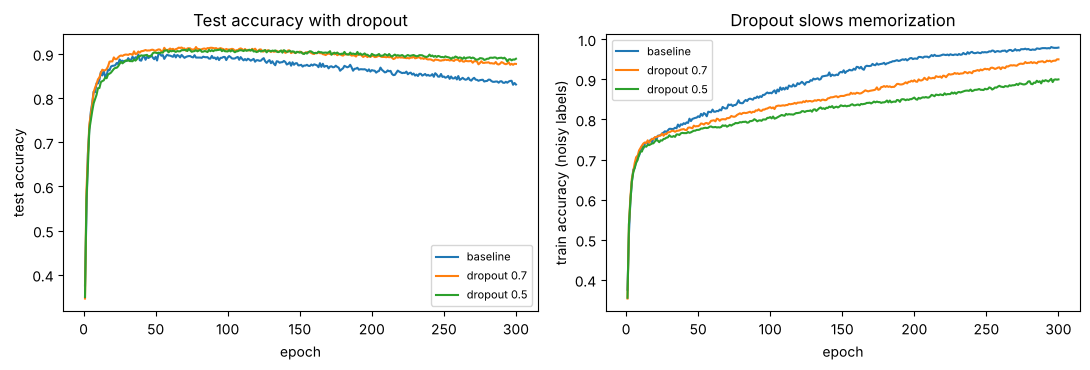

setting        | final train acc | final test acc
baseline       |           0.979 | 0.831
dropout 0.7    |           0.950 | 0.877
dropout 0.5    |           0.900 | 0.889


In [6]:
drop_names = ['baseline', 'dropout 0.7', 'dropout 0.5']
drop_runs = [base, runs('dropout 0.7', keep=0.7), runs('dropout 0.5', keep=0.5)]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, rs in zip(drop_names, drop_runs):
    axes[0].plot(epochs_axis, mean_curve(rs, 'test_acc'), label=name)
    axes[1].plot(epochs_axis, mean_curve(rs, 'train_acc'), label=name)
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('test accuracy'); axes[0].set_title('Test accuracy with dropout'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('train accuracy (noisy labels)'); axes[1].set_title('Dropout slows memorization'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/dropout.png', dpi=110)
plt.show()

print("setting        | final train acc | final test acc")
for name, rs in zip(drop_names, drop_runs):
    print(f"{name:14s} | {mean_curve(rs, 'train_acc')[-1]:15.3f} | {mean_curve(rs, 'test_acc')[-1]:.3f}")

**Reading the output.** The expected activation is preserved by the $1/p_{\text{keep}}$ rescaling, and the dropout backward pass is verified numerically. Dropout slows the growth of
training accuracy (the network has a harder time memorizing the wrong labels) and ends with a clearly better test accuracy than the unregularized baseline. In this small, noisy
setting it is less effective than a well-chosen weight decay, which is common: different regularizers suit different problems, and they can be **combined** (Section 6).

## 5. Mini-batch gradient descent

So far we updated the weights once per **epoch** (a full pass over the training set), using the average gradient of *all* examples. The alternatives:

| Method | Examples per update | Updates per epoch (300 examples) | Character |
|---|---|---|---|
| Full-batch | 300 | 1 | exact gradient, smooth, but few updates |
| Mini-batch | e.g. 20 | 15 | slightly noisy gradient, many updates |
| Stochastic (batch = 1) | 1 | 300 | very noisy, most updates |

A gradient estimated from a handful of examples is a noisy but **unbiased** estimate of the full gradient, and it is far cheaper — so for the same amount of computation we can take many more steps.
The noise is the price. In practice a mini-batch of tens or hundreds of examples is the standard compromise, and it also maps well onto matrix hardware (one matrix product per batch).

We train with the same learning rate and several batch sizes and compare progress **per epoch**.

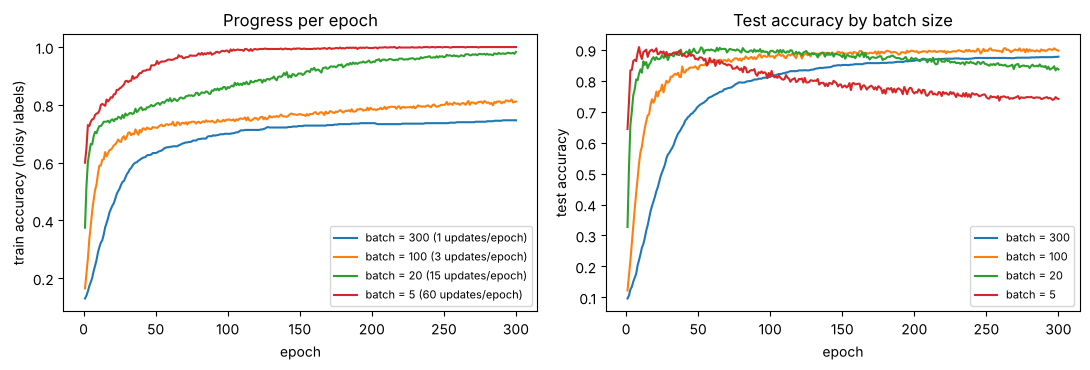

batch size | updates/epoch | train acc @ epoch 50 | train acc @ epoch 300 | best test acc | final test acc
       300 |             1 |                0.633 |                 0.747 |         0.878 | 0.878
       100 |             3 |                0.722 |                 0.812 |         0.905 | 0.897
        20 |            15 |                0.802 |                 0.983 |         0.908 | 0.837
         5 |            60 |                0.940 |                 1.000 |         0.909 | 0.741


In [7]:
batch_sizes = [300, 100, 20, 5]
batch_runs = {300: runs('batch 300 (full)', seeds=range(2), batch=300),
              100: runs('batch 100', seeds=range(2), batch=100),
              20: base[:2],
              5: runs('batch 5', seeds=range(2), batch=5)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for bs in batch_sizes:
    axes[0].plot(epochs_axis, mean_curve(batch_runs[bs], 'train_acc'), label=f'batch = {bs} ({300 // bs} updates/epoch)')
    axes[1].plot(epochs_axis, mean_curve(batch_runs[bs], 'test_acc'), label=f'batch = {bs}')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('train accuracy (noisy labels)'); axes[0].set_title('Progress per epoch'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('test accuracy'); axes[1].set_title('Test accuracy by batch size'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/batch_sizes.png', dpi=110)
plt.show()

print("batch size | updates/epoch | train acc @ epoch 50 | train acc @ epoch 300 | best test acc | final test acc")
for bs in batch_sizes:
    tr_c, te_c = mean_curve(batch_runs[bs], 'train_acc'), mean_curve(batch_runs[bs], 'test_acc')
    print(f"{bs:10d} | {300 // bs:13d} | {tr_c[49]:20.3f} | {tr_c[-1]:21.3f} | {te_c.max():13.3f} | {te_c[-1]:.3f}")

**Reading the output.** With the same learning rate, smaller batches make much more progress per epoch simply because they take more steps. The full-batch run (one update per epoch) ends at
about 75% training accuracy, which is roughly the share of *correct* labels: it has captured the signal but not yet the noise, so it never memorizes and its test accuracy stays at about 0.88.
Batch size 5 fits the training set perfectly (1.000) and, with no regularization, memorizes the most noise, ending with the worst test accuracy (about 0.74). So batch size also changes *how fast* overfitting arrives,
which is why batch size, learning rate and regularization are tuned together. (Best-epoch test accuracy is similar for all batch sizes, about 0.88 to 0.91.)

## 6. Putting it together

Finally the methods side by side, averaged over 5 random initializations (the data are the same; only the network's starting weights and the batch order differ).

method                   | mean test accuracy | std over seeds
baseline (last epoch)    |              0.831 | 0.009
early stopping           |              0.894 | 0.003
L2  (lambda = 1e-2)      |              0.927 | 0.005
dropout (keep = 0.5)     |              0.889 | 0.013
dropout + L2             |              0.915 | 0.003


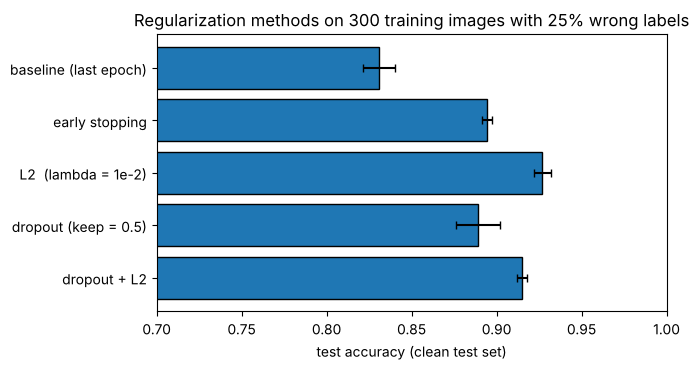

In [8]:
combo = runs('dropout 0.5 + L2 1e-2', keep=0.5, l2=1e-2)
l2_best = l2_runs[2]
dropout_best = drop_runs[2]

methods = {
    'baseline (last epoch)':        [r['test_acc'][-1] for r in base],
    'early stopping':               es_test,
    'L2  (lambda = 1e-2)':          [r['test_acc'][-1] for r in l2_best],
    'dropout (keep = 0.5)':         [r['test_acc'][-1] for r in dropout_best],
    'dropout + L2':                 [r['test_acc'][-1] for r in combo],
}

print("method                   | mean test accuracy | std over seeds")
for name, vals in methods.items():
    print(f"{name:24s} | {np.mean(vals):18.3f} | {np.std(vals):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(methods)
ax.barh(names, [np.mean(v) for v in methods.values()], xerr=[np.std(v) for v in methods.values()], edgecolor='k', capsize=3)
ax.set_xlim(0.7, 1.0); ax.invert_yaxis(); ax.set_xlabel('test accuracy (clean test set)')
ax.set_title('Regularization methods on 300 training images with 25% wrong labels')
plt.tight_layout()
plt.savefig('outputs/methods_comparison.png', dpi=110)
plt.show()

**Reading the output.** Every regularization method beats the unregularized baseline's final accuracy, and the differences are larger than the seed-to-seed spread (the error bars).
In this experiment, weight decay alone and dropout + weight decay are the best, early stopping recovers a good part of the loss for free, and dropout alone helps moderately.
(Caveat: this is one small, noisy dataset and one set of hyper-parameters; the ranking can change on other problems, so treat it as an illustration of the *mechanisms*, not a universal ranking.)

## Summary

| Idea | What it does | Key formula / rule |
|---|---|---|
| Overfitting | network memorizes noise; train ↑, test ↓ | gap between train and test performance |
| Validation set | untouched data to choose epochs / hyper-parameters | never tune on the test set |
| Early stopping | stop at the best validation epoch | free, needs held-out data |
| L2 / weight decay | shrink weights each step | $w\leftarrow(1-\alpha\lambda)w-\alpha\,\partial E/\partial w$ |
| Dropout | randomly silence hidden units in training only | mask $m\in\{0,1/p\}$; same mask in backprop; off at test |
| Mini-batches | update from small groups of examples | many cheap, noisy updates per epoch |

**Key takeaway:** the goal of training is not a low training error but a low error on *new* data. Everything in this chapter is a way to make the network prefer
signal over noise.